In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#locators for major and minor tick marks
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
#Insert complete path to the excel file and index of the worksheet 9Mar2021_batch
#Using usecols, skiprows to account for formatting.
#Giving the columns the correct names
columns = ['Time' , 'Agit' , 'Airflow' , 'DO' , 'pH' , 'Temp']
#use names=columns in df=...
df = pd.read_excel("testplots.xls", sheet_name = 0,header=None, names=columns , usecols="A,C,E,G,M,O", skiprows=6)


In [8]:
print(df.head())

    Time        Agit    Airflow         DO         pH Temp
0  0.019  275.250488   9.956258  99.728104  19.993050  NaN
1  0.036  262.440704  10.014960  85.079193  19.997450  NaN
2  0.053  256.369904  10.003760  61.674938  19.986191  NaN
3  0.069  252.991806  10.524250  75.338181  19.877029  NaN
4  0.086  251.903702   9.481812  83.624496  19.768351  NaN


In [9]:
print(df.tail())

        Time        Agit    Airflow         DO         pH Temp
1482  24.753  279.460205   4.213682  39.895321  18.247370  NaN
1483  24.769  286.029205   8.416351  38.991230  18.258631  NaN
1484  24.786  285.446808   9.139732  41.533550  18.261080  NaN
1485  24.803  267.907196  10.277020  41.329620  18.269890  NaN
1486  24.819  280.670105   9.947827  36.462509  18.283600  NaN


Text(0.5, 1.0, 'NUCARF X041724')

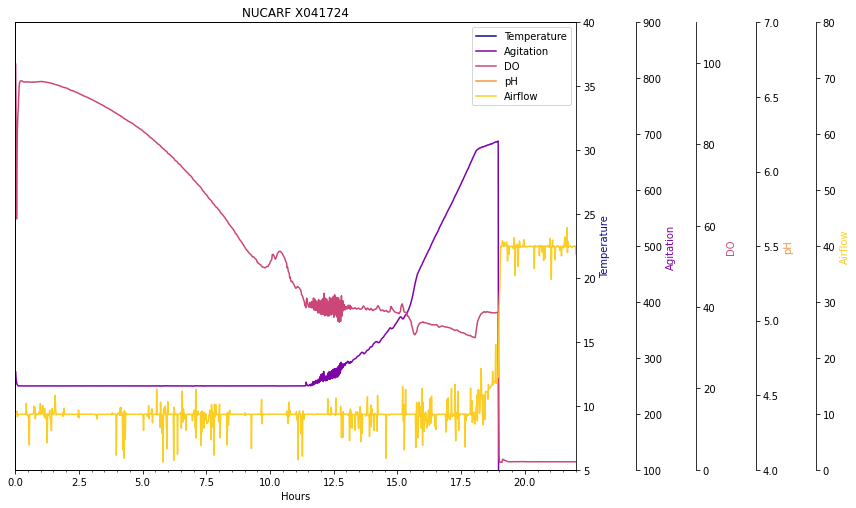

In [10]:
#%% Set up the plot 

fig, host = plt.subplots(figsize=(12,7)) # (width, height) in inches

# Define the number of secondary axis here    

par1 = host.twinx()

par2 = host.twinx()

par3 = host.twinx()

par4 = host.twinx()

# --- NEW: Move host axis to the right ---
host.yaxis.tick_right()
host.yaxis.set_label_position("right")
host.spines['left'].set_visible(False)  # Clean up the left side
# Define the limits of each axis plot here

host.set_xlim(0, 22)      # Time check maximum hours use print(df.tail())

host.set_ylim(5, 40)     # Temperature

par1.set_ylim(100, 900)  # Agitation

par2.set_ylim(0, 110)    # DO

par3.set_ylim(4, 7)      # pH

par4.set_ylim(0, 80)  # Airflow

# Set the label of the different  axis here

host.set_xlabel("Hours")

host.set_ylabel("Temperature")

par1.set_ylabel("Agitation")

par2.set_ylabel("DO")

par3.set_ylabel("pH")

par4.set_ylabel("Airflow")

# Set the colormaps 

color1 = plt.cm.plasma(0) 

color2 = plt.cm.plasma(0.25)
#Adjusting DO color default is 0.5
color3 = plt.cm.plasma(0.5)
#try to make pH pink default is 0.75
color4 = plt.cm.plasma(0.75)

color5 = plt.cm.plasma(0.9)

# Plot the data
p1, = host.plot(df.Time, df.Temp, color=color1, label="Temperature")

p2, = par1.plot(df.Time, df.Agit,  color=color2, label="Agitation")

p3, = par2.plot(df.Time, df.DO,  color=color3,  label="DO")

p4, =par3.plot(df.Time, df.pH,  color=color4,  label="pH")

p5, =par4.plot(df.Time, df.Airflow, color=color5,  label= "Airflow")

lns = [p1, p2, p3, p4, p5]

host.legend(handles=lns, loc='best')

# --- REPLACED: Offset all 5 axes to the right ---
host.spines['right'].set_position(('outward', 0))
par1.spines['right'].set_position(('outward', 60))
par2.spines['right'].set_position(('outward', 120))
par3.spines['right'].set_position(('outward', 180))
par4.spines['right'].set_position(('outward', 240))


#Default x ticks
#no x ticks are #'d out
#Auto minor ticks
host.xaxis.set_minor_locator(AutoMinorLocator())
#par2.xaxis.set_ticks([])

#par3.xaxis.set_ticks([])

#par4.xaxis.set_ticks([])

#axis color

host.yaxis.label.set_color(p1.get_color())

par1.yaxis.label.set_color(p2.get_color())

par2.yaxis.label.set_color(p3.get_color())

par3.yaxis.label.set_color(p4.get_color())

par4.yaxis.label.set_color(p5.get_color())

# Adjust spacings w.r.t. figsize

fig.tight_layout()
plt.title("NUCARF X041724")
#%% Save the figure 
#Change this to a descriptive name
#plt.savefig("test1_.pdf")